# Week 6 · Day 2 — Daily Challenge
## NumPy, Pandas, and Matplotlib Integration

**Goal:** Create a reproducible synthetic monthly-temperature dataset for 10 cities, analyze annual averages, and communicate the results through visualizations.

**Important:** Temperatures are randomly generated and **do not represent actual climate records**.

## 1. Import libraries and prepare data
We use a fixed random seed so that the results are reproducible. Each temperature is sampled independently from a uniform distribution between −5°C and 35°C.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

rng = np.random.default_rng(42)
cities = ["New York", "London", "Tokyo", "Paris", "Sydney", "Toronto", "Berlin", "Mumbai", "Cairo", "São Paulo"]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

temperatures = rng.uniform(-5, 35, size=(10, 12))
df = pd.DataFrame(temperatures, index=cities, columns=months)
df.index.name = "City"

print("Dataset shape:", df.shape)
print("Temperature range:", f"{df.to_numpy().min():.2f}°C to {df.to_numpy().max():.2f}°C")
display(df.round(2))

Dataset shape: (10, 12)
Temperature range: -4.71°C to 34.02°C


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
City,,,,,,,,,,,,
New York,25.96,12.56,29.34,22.89,-1.23,34.02,25.45,26.44,0.12,13.02,9.83,32.07
London,20.75,27.91,12.74,4.09,17.18,-2.45,28.11,20.27,25.32,9.18,33.83,30.72
Tokyo,26.14,2.79,13.67,-3.25,1.17,22.32,24.79,33.70,8.03,9.82,13.78,2.58
Paris,0.20,14.03,4.08,21.79,12.49,28.31,23.01,7.49,28.29,27.19,10.50,6.53
Sydney,22.30,0.59,3.00,-4.71,26.48,21.59,23.21,26.23,13.36,17.75,0.59,-0.42
Toronto,21.74,13.84,17.61,25.60,20.39,17.14,17.37,7.16,-3.77,12.47,3.58,11.34
Berlin,29.14,4.36,-2.67,6.26,6.74,21.48,17.28,26.36,21.57,11.26,27.56,1.68
Mumbai,-4.09,-1.40,23.89,13.48,1.45,15.04,1.09,22.85,12.85,10.24,7.06,20.21
Cairo,9.47,-1.49,-0.28,33.48,31.34,22.99,5.63,33.77,26.15,23.68,12.97,5.89


## 2. Analyze annual averages
Each city has 12 monthly observations. Calculate its arithmetic mean across columns (`axis=1`), then use `idxmax()` and `idxmin()` to identify the highest and lowest means.

In [2]:
annual_avg = df.mean(axis=1).sort_values(ascending=False)
warmest_city = annual_avg.idxmax()
coolest_city = annual_avg.idxmin()

print("Annual average temperature by city (°C):")
display(annual_avg.rename("Annual Average (°C)").round(2).to_frame())
print(f"Highest annual average: {warmest_city} ({annual_avg.loc[warmest_city]:.2f}°C)")
print(f"Lowest annual average: {coolest_city} ({annual_avg.loc[coolest_city]:.2f}°C)")

Annual average temperature by city (°C):


,Annual Average (°C)
City,
New York,19.21
London,18.97
Cairo,16.97
São Paulo,15.38
Paris,15.33
Berlin,14.25
Toronto,13.71
Tokyo,12.96
Sydney,12.50


Highest annual average: New York (19.21°C)
Lowest annual average: Mumbai (10.22°C)


## 3. Visualize temperature trends
The line plot compares monthly temperature patterns. The bar chart compares annual means, and the heatmap makes it easier to spot higher and lower simulated values.

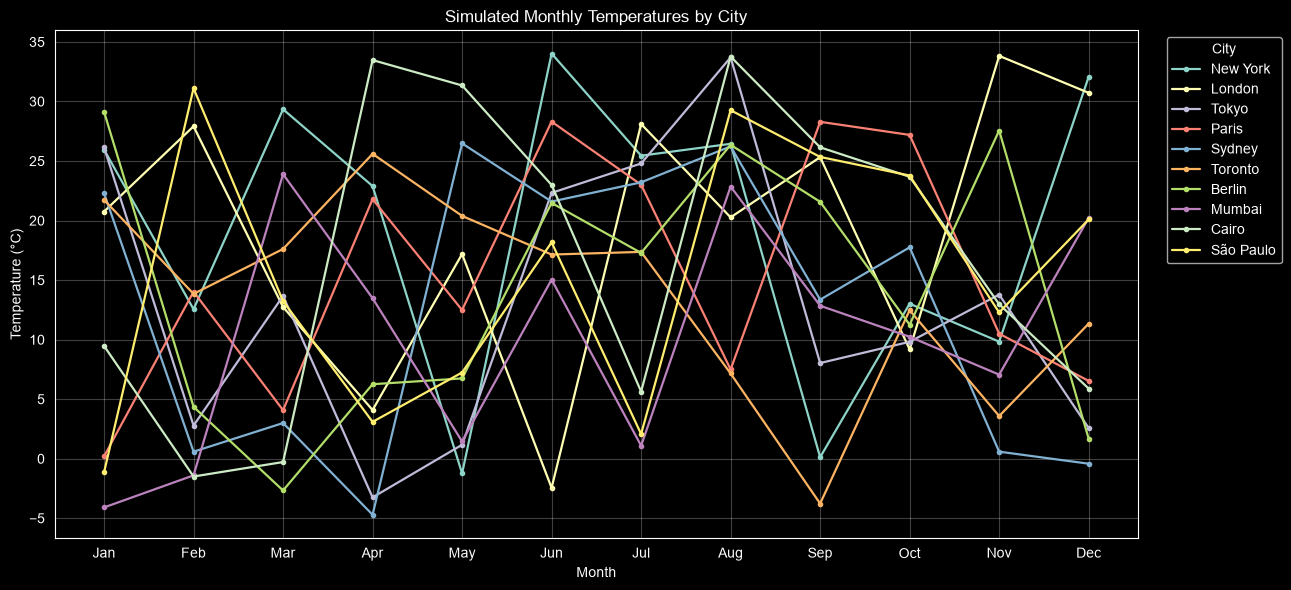

In [3]:
fig, ax = plt.subplots(figsize=(13, 6))
for city in df.index:
    ax.plot(months, df.loc[city], marker="o", markersize=3, linewidth=1.6, label=city)
ax.set(title="Simulated Monthly Temperatures by City", xlabel="Month", ylabel="Temperature (°C)")
ax.grid(alpha=0.25)
ax.legend(title="City", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

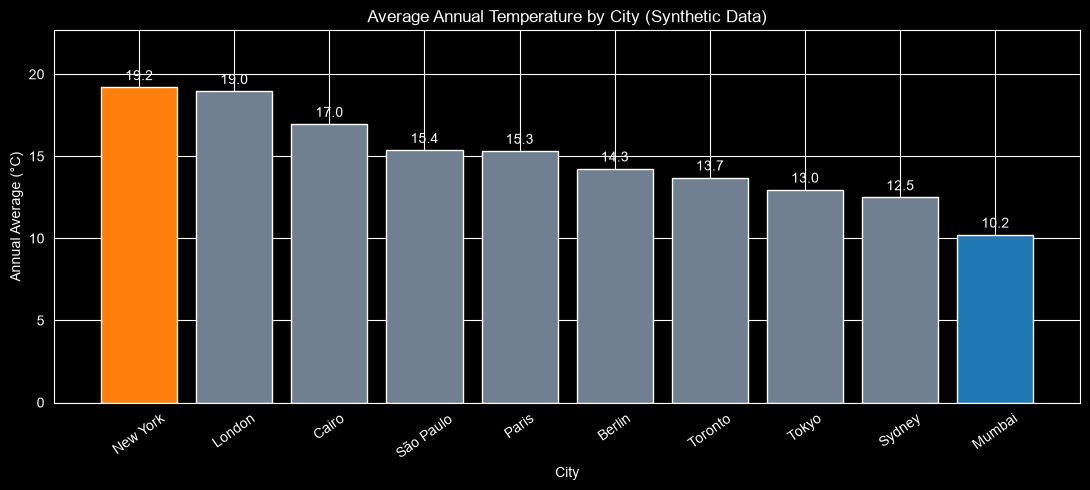

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
colors = ["tab:orange" if city == warmest_city else "tab:blue" if city == coolest_city else "slategray" for city in annual_avg.index]
bars = ax.bar(annual_avg.index, annual_avg.values, color=colors)
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set(title="Average Annual Temperature by City (Synthetic Data)", xlabel="City", ylabel="Annual Average (°C)")
ax.tick_params(axis="x", rotation=35)
ax.set_ylim(top=max(annual_avg.max() * 1.18, annual_avg.max() + 2))
fig.tight_layout()
plt.show()

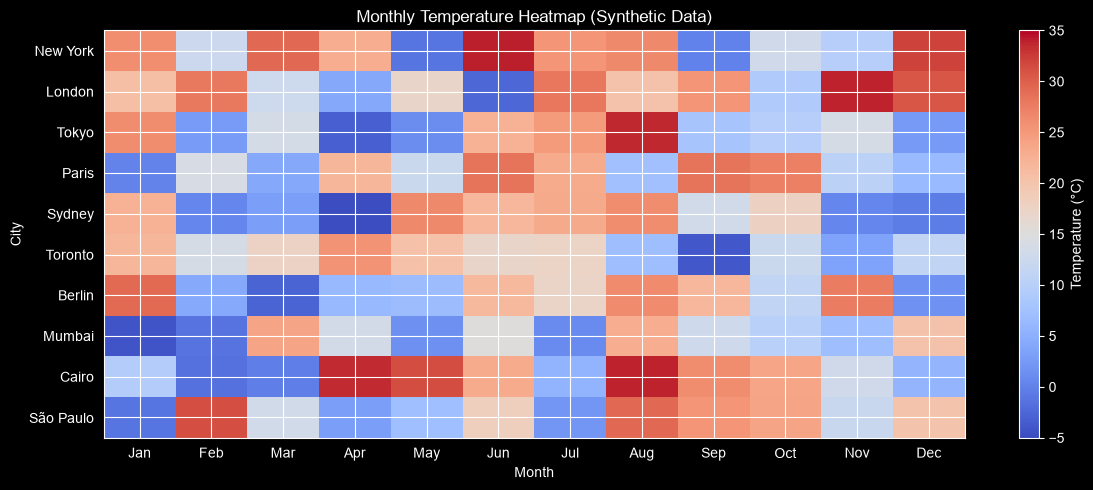

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
heat = ax.imshow(df.to_numpy(), aspect="auto", cmap="coolwarm", vmin=-5, vmax=35)
ax.set_xticks(range(len(months)), months)
ax.set_yticks(range(len(cities)), cities)
ax.set(title="Monthly Temperature Heatmap (Synthetic Data)", xlabel="Month", ylabel="City")
fig.colorbar(heat, ax=ax, label="Temperature (°C)")
fig.tight_layout()
plt.show()

## 4. Brief report and interpretation
The following report is calculated directly from the simulated dataset.

In [6]:
monthly_avg = df.mean(axis=0)
peak_month = monthly_avg.idxmax()
low_month = monthly_avg.idxmin()
spread = annual_avg.max() - annual_avg.min()

report = f"""### Summary of findings

- **Warmest simulated city:** {warmest_city}, with an annual average of **{annual_avg.loc[warmest_city]:.2f}°C**.
- **Coolest simulated city:** {coolest_city}, with an annual average of **{annual_avg.loc[coolest_city]:.2f}°C**.
- **Difference between annual averages:** **{spread:.2f}°C**.
- **Highest cross-city monthly mean:** **{peak_month}** ({monthly_avg.loc[peak_month]:.2f}°C).
- **Lowest cross-city monthly mean:** **{low_month}** ({monthly_avg.loc[low_month]:.2f}°C).

**Interpretation:** The line chart displays month-to-month fluctuations for each city; the bar chart makes annual averages easy to compare; and the heatmap highlights relative temperature variation across cities and months. Since each month was sampled independently from a uniform distribution, these differences are random and **should not be interpreted as real-world seasonal patterns or geographic climate differences**.
"""
display(Markdown(report))

### Summary of findings

- **Warmest simulated city:** New York, with an annual average of **19.21°C**.
- **Coolest simulated city:** Mumbai, with an annual average of **10.22°C**.
- **Difference between annual averages:** **8.98°C**.
- **Highest cross-city monthly mean:** **Aug** (23.35°C).
- **Lowest cross-city monthly mean:** **Feb** (10.43°C).

**Interpretation:** The line chart displays month-to-month fluctuations for each city; the bar chart makes annual averages easy to compare; and the heatmap highlights relative temperature variation across cities and months. Since each month was sampled independently from a uniform distribution, these differences are random and **should not be interpreted as real-world seasonal patterns or geographic climate differences**.


## 5. Conclusions

This project demonstrates NumPy array generation, Pandas DataFrame creation and row-wise aggregation, and Matplotlib visualizations. A fixed random seed makes the analysis reproducible. To study real climate trends, replace these simulated values with observed monthly weather data.